In [9]:
from math import *
import numpy as np
import matplotlib.pyplot as plt
from time import time as timeclock

1001


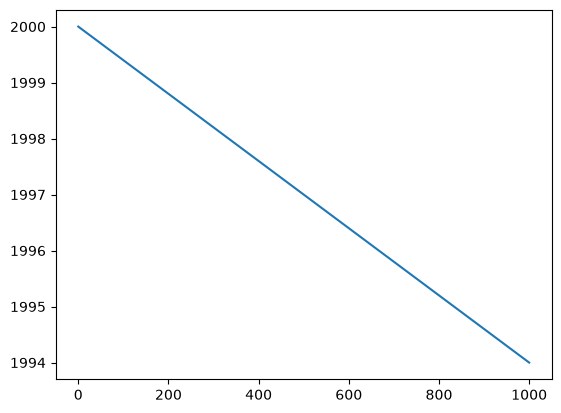

In [10]:
denw = 1000 #kg/m3 # Density of water
Lh = 330000 #J/kg # Latent heat 
h0 = 1 #m # Drained hydrolically active sediment thickness #hs0???
qgeo = 0.065 #W/m2 # geothermal heat flux
Tmelt = 273 #K
Tsurf = -20 + Tmelt
delT = -20 #K #Difference bw surface and melt
mu = 0.5 #sliding param
k = 2 #W/mK # Thermal conductivity
Ce = 0.0345 # coeff of compressibility

er = 0.78 # void reference parameter
Nr = 1000 #Pa # reference value for effective pressure

dx = 1
x = np.arange(0,1000 + dx,dx) 
print(len(x))
Hi = np.array([np.max([2000 - 0.006*xi,100]) for xi in x])  # meters # from Haseloff 2025
ui = 1*x
Ni = 20.85 - 1e-6*x #MPa

hsi = h0
u0 = 1 #m/yr #value for calculating taub
taub = mu*Ni*ui/np.sqrt(ui**2 + u0**2) # basal shear resistance, combined with u to get frictional heating/unit area

def Nfrome(ei):
    N = Nr*np.exp((er-ei)/Ce)
    return N

def efromN(Ni):
    ei = er - Ce*np.log(Ni/Nr)
    return ei 


def dedt(Hi,ui,ei):
    Ni = Nfrome(ei) #effective pressure in terms of void ratio
    taub = Ni*mu*ui/np.sqrt(ui**2 + u0**2) #?
    de = 1/(hsi*denw*Lh) * (taub*ui + qgeo - k*delT/Hi)
    return de

dedt(Hi,ui,efromN(Ni))
plt.plot(x,Hi)

2.0754449367523193

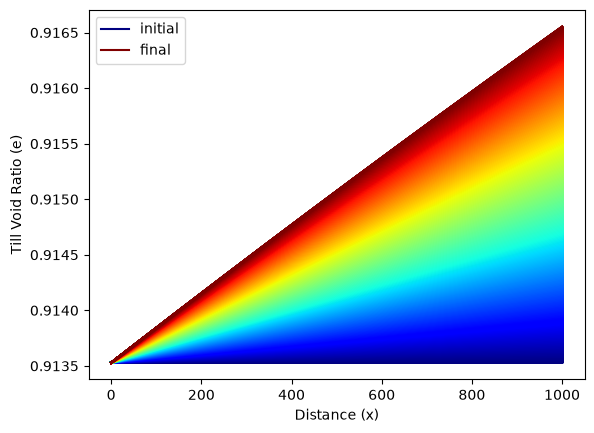

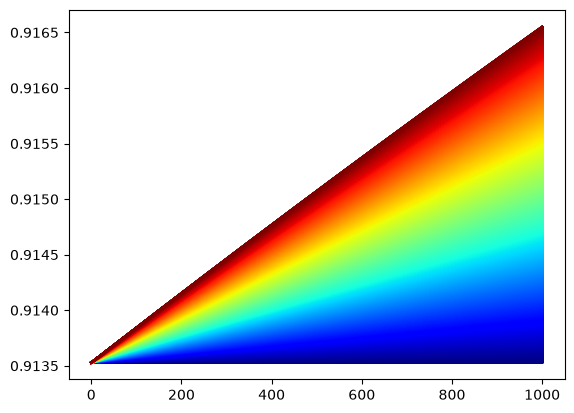

In [11]:
# Test with forward euler
ti = timeclock()
dt = 0.01
tottime = 100
time = np.arange(tottime/dt)

ei = efromN(Ni)
eold = np.copy(ei)
earr_fe = np.zeros([len(time),len(ei)])
earr_fe[0,:] = ei

fig,ax = plt.subplots()
colors = plt.cm.jet(np.linspace(0,1,len(time)))

for i in range(len(time)-1):
    t = time[i]
    enew = eold + dt*dedt(Hi,ui,eold)
    eold = np.copy(enew)
    earr_fe[i+1,:] = eold
    if i == 0:
        ax.plot(x,eold,color=colors[int(t)],label = "initial")
    elif i == len(time)-2:
        ax.plot(x,eold,color=colors[int(t)], label = "final")
    else:
        ax.plot(x,eold,color=colors[int(t)])
plt.legend()
plt.xlabel("Distance (x)")
plt.ylabel("Till Void Ratio (e)")
tf = timeclock()
#ax.plot(ei)

fig,ax = plt.subplots()
#plt.spy(earr)
for i in range(len(time)):
    ax.plot(x,earr_fe[i,:],color=colors[i])
    x = x

tf = timeclock()
time_fe = tf - ti
time_fe

2.0721921920776367

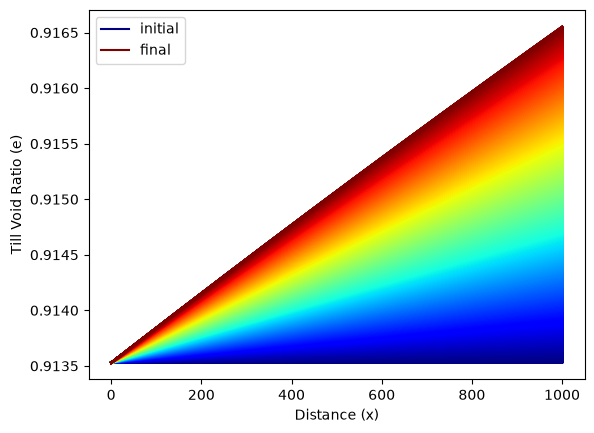

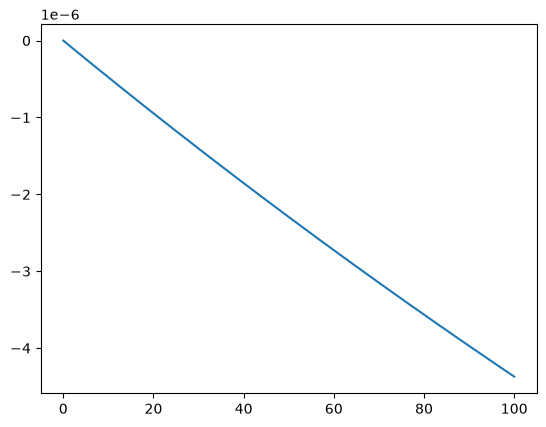

In [12]:
# Test with explicit midpoint method
ti = timeclock()
dt = 0.01
tottime = 100
time = np.arange(tottime/dt)*dt

ei = efromN(Ni)
eold = np.copy(ei)
earr_mp = np.zeros([len(time),len(ei)])
earr_mp[0,:] = ei

fig,ax = plt.subplots()
colors = plt.cm.jet(np.linspace(0,1,len(time)))

for i in range(len(time)-1): 
    t = time[i]
    enew = eold + dt*dedt(Hi,ui, eold + 0.5*dt*dedt(Hi,ui,eold) )
    eold = np.copy(enew)
    earr_mp[i+1,:] = eold
    if i == 0:
        ax.plot(x,eold,color=colors[int(t/dt)],label = "initial")
    elif i == len(time)-2:
        ax.plot(x,eold,color=colors[int(t/dt)], label = "final")
    else:
        ax.plot(x,eold,color=colors[int(t/dt)])

plt.legend()
plt.xlabel("Distance (x)")
plt.ylabel("Till Void Ratio (e)")
tf = timeclock()

fig,ax=plt.subplots()
#plt.plot(time,[np.sum([earr_mp[i,j] - earr_fe[i,j] for j in len(ei)]) for i in len(time)])
mp_fe = [np.sum([earr_mp[i,j] - earr_fe[i,j] for j in range(1,len(ei))]) for i in range(len(time))]
plt.plot(time[:],mp_fe)
#[earr_mp[1,j] - earr_fe[1,j] for j in range(1,len(ei))]

time_mp = tf - ti
time_mp

1000
2000
3000
4000
5000
6000
7000
8000
9000


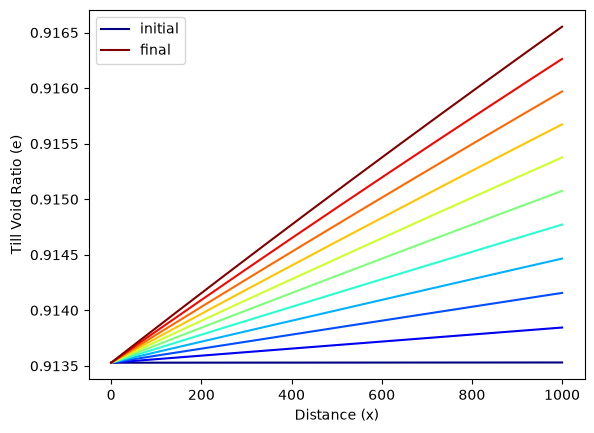

0.4188497066497803

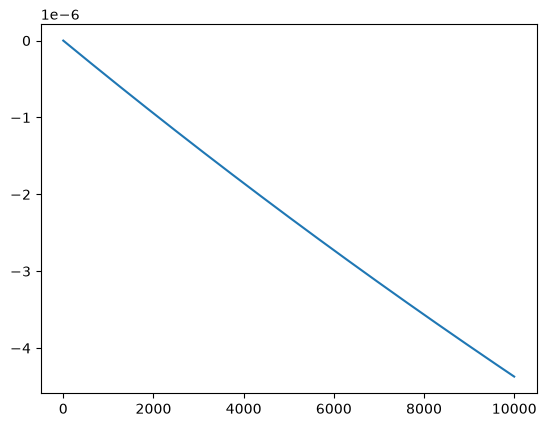

In [13]:
# Test with RK4
ti = timeclock()
dt = 0.01
tottime = 100
time = np.arange(tottime/dt)
x = np.arange(len(ei))

ei = efromN(Ni)
eold = np.copy(ei)
earr_ab3 = np.zeros([len(time),len(ei)])
earr_ab3[0,:] = ei

fig,ax = plt.subplots()
colors = plt.cm.jet(np.linspace(0,1,len(time)))

for i in range(len(time)-1): 
    t = time[i]
    k1 = dedt(Hi,ui,eold)
    k2 = dedt(Hi,ui,eold + dt/2*k1)
    k3 = dedt(Hi,ui,eold + dt/2*k2)
    k4 = dedt(Hi,ui,eold + dt*k3)
    enew = eold + dt/6*(k1 + 2*k2 + 2*k3 + k4)

    eold = np.copy(enew)
    earr_ab3[i+1,:] = eold
    if i == 0:
        ax.plot(x,eold,color=colors[int(t)],label = "initial")
    elif i == len(time)-2:
        ax.plot(x,eold,color=colors[int(t)], label = "final")
    elif (i % 1000) == 0:
        ax.plot(x,eold,color=colors[int(t)])
        print(i)
    else:
        i = i
plt.legend()
plt.xlabel("Distance (x)")
plt.ylabel("Till Void Ratio (e)")
plt.show()
tf = timeclock()

fig,ax=plt.subplots()
#plt.plot(time,[np.sum([earr_mp[i,j] - earr_fe[i,j] for j in len(ei)]) for i in len(time)])
ab3_fe = [np.sum([earr_ab3[i,j] - earr_fe[i,j] for j in range(1,len(ei))]) for i in range(len(time))]
ab3_mp = [np.sum([earr_ab3[i,j] - earr_mp[i,j] for j in range(1,len(ei))]) for i in range(len(time))]
plt.plot(time[:],ab3_fe)
#[earr_mp[1,j] - earr_fe[1,j] for j in range(1,len(ei))]

time_rk4 = tf - ti
time_rk4

0.10869598388671875

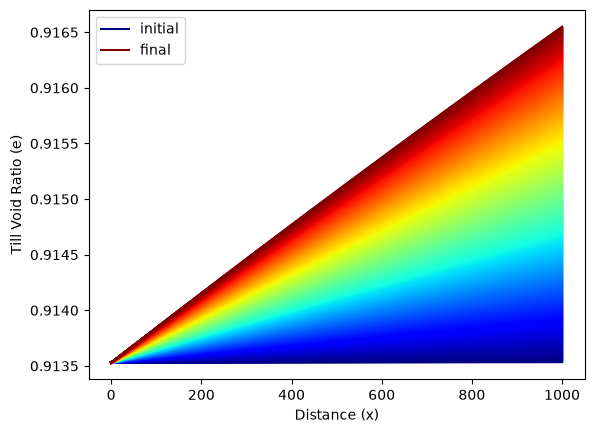

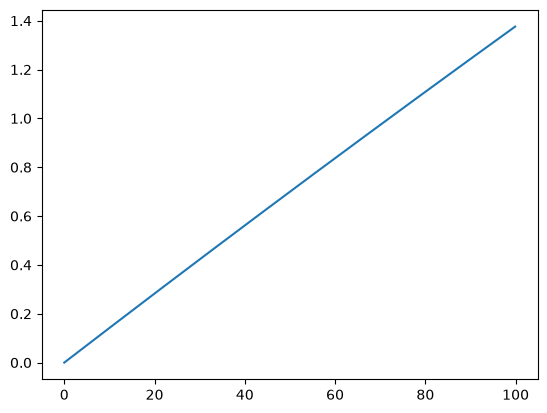

In [14]:
# Test with two step Adams-Bashforth, starting with explicit midpoint
ti = timeclock()
dt = 0.1
tottime = 100
time = np.arange(tottime/dt)*dt

ei = efromN(Ni)
eold = np.copy(ei)
earr_ab2 = np.zeros([len(time),len(ei)])
earr_ab2[0,:] = ei

fig,ax = plt.subplots()
colors = plt.cm.jet(np.linspace(0,1,len(time)))

for i in range(len(time)-1): 
    t = time[i]
    if i == 0 or 1: #midpoint for the first two steps
        enew = eold + dt*dedt(Hi,ui, eold + 0.5*dt*dedt(Hi,ui,eold) )
    else: # a-b else
        enew = eold + 1.5*dt*dedt(Hi,ui,eold) - 0.5*dt*dedt(Hi,ui,earr_ab2[i-1])

    eold = np.copy(enew)
    earr_ab2[i+1,:] = eold
    if i == 0:
        ax.plot(x,eold,color=colors[int(t/dt)],label = "initial")
    elif i == len(time)-2:
        ax.plot(x,eold,color=colors[int(t/dt)], label = "final")
    else:
        ax.plot(x,eold,color=colors[int(t/dt)])
plt.legend()
plt.xlabel("Distance (x)")
plt.ylabel("Till Void Ratio (e)")
tf = timeclock()

fig,ax=plt.subplots()
#plt.plot(time,[np.sum([earr_mp[i,j] - earr_fe[i,j] for j in len(ei)]) for i in len(time)])
ab2_fe = [np.sum([earr_ab2[i,j] - earr_fe[i,j] for j in range(1,len(ei))]) for i in range(len(time))]
plt.plot(time[:],ab2_fe)
#[earr_mp[1,j] - earr_fe[1,j] for j in range(1,len(ei))]

time_ab2 = tf - ti
time_ab2

1000
2000
3000
4000
5000
6000
7000
8000
9000


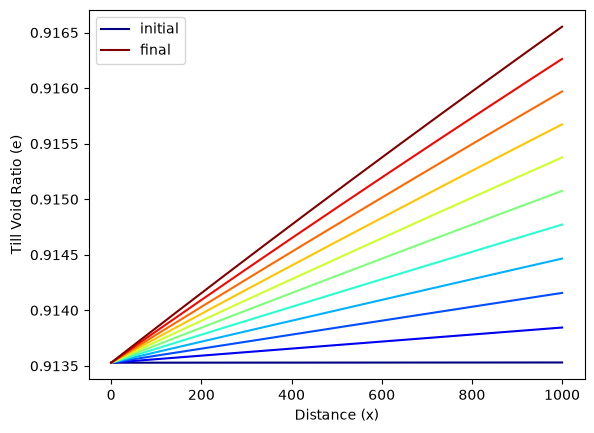

0.218275785446167

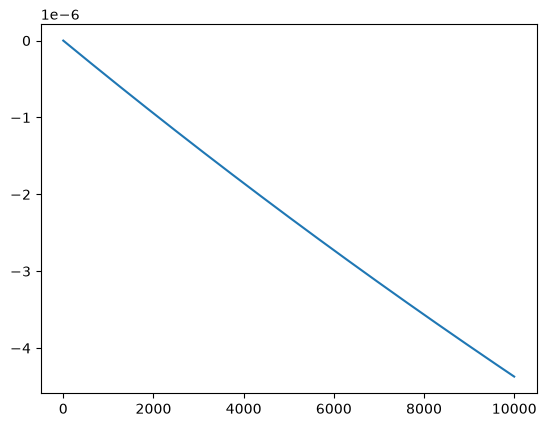

In [15]:
# Test with three step Adams-Bashforth, starting with explicit midpoint
ti = timeclock()
dt = 0.01
tottime = 100
time = np.arange(tottime/dt)
x = np.arange(len(ei))

ei = efromN(Ni)
eold = np.copy(ei)
earr_ab3 = np.zeros([len(time),len(ei)])
earr_ab3[0,:] = ei

fig,ax = plt.subplots()
colors = plt.cm.jet(np.linspace(0,1,len(time)))

for i in range(len(time)-1): 
    t = time[i]
    if i == 0 or 1 or 2: #midpoint for the first two steps
        enew = eold + dt*dedt(Hi,ui, eold + 0.5*dt*dedt(Hi,ui,eold) )
    else: # a-b else
        enew = eold + 23/12*dt*dedt(Hi,ui,eold) - 4/3*dt*dedt(Hi,ui,earr_ab2[i-1,:]) + 5/12*dt*dedt(Hi,ui,earr_ab2[i-2,:])

    eold = np.copy(enew)
    earr_ab3[i+1,:] = eold
    if i == 0:
        ax.plot(x,eold,color=colors[int(t)],label = "initial")
    elif i == len(time)-2:
        ax.plot(x,eold,color=colors[int(t)], label = "final")
    elif (i % 1000) == 0:
        ax.plot(x,eold,color=colors[int(t)])
        print(i)
    else:
        i = i
plt.legend()
plt.xlabel("Distance (x)")
plt.ylabel("Till Void Ratio (e)")
plt.show()
tf = timeclock()

fig,ax=plt.subplots()
#plt.plot(time,[np.sum([earr_mp[i,j] - earr_fe[i,j] for j in len(ei)]) for i in len(time)])
ab3_fe = [np.sum([earr_ab3[i,j] - earr_fe[i,j] for j in range(1,len(ei))]) for i in range(len(time))]
ab3_mp = [np.sum([earr_ab3[i,j] - earr_mp[i,j] for j in range(1,len(ei))]) for i in range(len(time))]
plt.plot(time[:],ab3_fe)
#[earr_mp[1,j] - earr_fe[1,j] for j in range(1,len(ei))]

time_ab3 = tf - ti
time_ab3

In [16]:
print(f"For timestep {dt}:")
print(f'- forward euler: {time_fe} sec')
print(f'- explicit midpoint: {time_mp} sec')
print(f'- Runge-Kutta 4: {time_rk4} sec')
print(f'- A-B two-step: {time_ab2} sec')
print(f'- A-B three-step: {time_ab3} sec')

For timestep 0.01:
- forward euler: 2.0754449367523193 sec
- explicit midpoint: 2.0721921920776367 sec
- Runge-Kutta 4: 0.4188497066497803 sec
- A-B two-step: 0.10869598388671875 sec
- A-B three-step: 0.218275785446167 sec
